# Combined CUJ: BigQuery Trace Search, Cost-Aware Routing & Pattern-to-Eval Discovery

This notebook walks through all five stages of the Combined CUJ pipeline:
1. **ADK Trace Ingestion & `eval_turns` Materialization** (`agent_events` -> `eval_turns`)
2. **Deterministic `S1` vs `S2` vs `S3` Trajectory Extraction Ablation** (`< 1,200` tokens at `$0` ingest LLM cost)
3. **BigQuery Dual Indexes (`SEARCH INDEX` + `AI.EMBED` + scale-aware `IVF` `VECTOR INDEX`) & 4-Layer Query Routing** (`AI.SEARCH` + RRF + Lazy `trace` hydration)
4. **Scoped `AI.GENERATE` Contradiction Verification & 8-Lever Eval Cost Cascade**
5. **Continuous Pattern Discovery -> `bigquery_agent_analytics.EvalSuite` Export & Adaptive Workbench HTML**

Set `DEMO_MOCK_LIVE=false` and `PROJECT_ID=<your-project>` to execute live against BigQuery (`US`) and Vertex AI.

In [1]:
import json
import os
from pathlib import Path
import sys

DEMO_DIR = Path.cwd()
if (DEMO_DIR / 'examples' / 'combined_cuj_trace_search_demo').exists():
  DEMO_DIR = DEMO_DIR / 'examples' / 'combined_cuj_trace_search_demo'
REPO_ROOT = DEMO_DIR.parents[1]

for p in (str(DEMO_DIR), str(REPO_ROOT / 'src')):
  if p not in sys.path:
    sys.path.insert(0, p)

DEMO_MOCK_LIVE = os.environ.get('DEMO_MOCK_LIVE', 'true').lower() == 'true'
PROJECT_ID = os.environ.get('PROJECT_ID', 'demo-project')
SHOW_RAW_PROJECT = os.environ.get('SHOW_RAW_PROJECT', 'false').lower() == 'true'
DISPLAY_PROJECT_ID = PROJECT_ID if SHOW_RAW_PROJECT else '<your-gcp-project>'
DATASET_ID = os.environ.get('DATASET_ID', 'combined_cuj_trace_search_demo')
TABLE_ID = os.environ.get('TABLE_ID', 'agent_events')
EVAL_TURNS_TABLE = os.environ.get('EVAL_TURNS_TABLE', 'eval_turns')
BQ_LOCATION = os.environ.get('BQ_LOCATION', 'US')
AGENT_LOCATION = os.environ.get('AGENT_LOCATION', 'global')
MODEL_NAME = os.environ.get('MODEL_NAME', 'gemini-4-hydrogen')
BQML_CONNECTION_ID = os.environ.get('BQML_CONNECTION_ID', '')

def _mask_proj(obj):
  if SHOW_RAW_PROJECT:
    return obj
  if isinstance(obj, str):
    out = obj
    if PROJECT_ID and PROJECT_ID != 'demo-project':
      out = out.replace(PROJECT_ID, 'demo-project')
    demo_str = str(DEMO_DIR)
    if demo_str and demo_str in out:
      out = out.replace(demo_str, 'examples/combined_cuj_trace_search_demo')
    repo_str = str(REPO_ROOT)
    if repo_str and repo_str in out:
      out = out.replace(repo_str, '.')
    home_str = str(Path.home())
    if home_str and home_str in out:
      out = out.replace(home_str, '~')
    return out
  if isinstance(obj, list):
    return [_mask_proj(v) for v in obj]
  if isinstance(obj, dict):
    return {k: _mask_proj(v) for k, v in obj.items()}
  return obj

out_dir = Path(
    os.environ.get(
        'NOTEBOOK_REPORTS_DIR',
        str(DEMO_DIR / 'reports' / 'notebook_run'),
    )
)
out_dir.mkdir(parents=True, exist_ok=True)
live_json_path = out_dir / 'live_demo_results.json'
search_json_path = out_dir / 'search_results.json'
pattern_json_path = out_dir / 'pattern_eval_report.json'
suite_json_path = out_dir / 'eval_dataset_generated.json'

print(
    f'Mode: {"OFFLINE MOCK-LIVE" if DEMO_MOCK_LIVE else "LIVE BIGQUERY"} | '
    f'Project: {DISPLAY_PROJECT_ID} | Dataset: {DATASET_ID} | '
    f'Output: {_mask_proj(str(out_dir))}'
)

Mode: LIVE BIGQUERY | Project: <your-gcp-project> | Dataset: bqaa_combined_cuj_demo | Output: examples/combined_cuj_trace_search_demo/reports/notebook_run


## Stage 1: ADK Enterprise Agent Scenarios & `eval_turns` Materialization

Runs 8 realistic enterprise customer-operations scenarios (happy path, `CARD_EXPIRED`, silent tool-to-response contradictions, `>= 3` retry loops hitting `DEADLINE_EXCEEDED`, and `> 8 KB` bloated audit dumps) via `BigQueryAgentAnalyticsPlugin`, then materializes `eval_turns` (`WRITE_TRUNCATE` / `CREATE OR REPLACE TABLE` for idempotency) with `has_error` and `root_agent`.

In [2]:
from agent.run_live_demo import run_demo

live_results = run_demo(
    project_id=PROJECT_ID,
    dataset_id=DATASET_ID,
    table_id=TABLE_ID,
    eval_turns_table=EVAL_TURNS_TABLE,
    location=BQ_LOCATION,
    agent_location=AGENT_LOCATION,
    model_name=MODEL_NAME,
    mock_live=DEMO_MOCK_LIVE,
    output_json=live_json_path,
)
eval_turns = live_results['eval_turns']
print(f'Materialized {len(eval_turns)} eval_turns rows -> {_mask_proj(str(live_json_path))}')

  [1/8] scn_01_healthy_refund -> sess_01_healthy_refund_20261124_200850


  [2/8] scn_02_exact_card_expired -> sess_02_exact_card_expired_20261124_200850


  [3/8] scn_03_silent_contradiction_refund -> sess_03_silent_contradiction_refund_20261124_200850


  [4/8] scn_04_deadline_retry_loop -> sess_04_deadline_retry_loop_20261124_200850


  [5/8] scn_05_bloated_audit_blob -> sess_05_bloated_audit_blob_20261124_200850


  [6/8] scn_06_multi_tool_policy_check -> sess_06_multi_tool_policy_check_20261124_200850


  [7/8] scn_07_permission_denied_lookup -> sess_07_permission_denied_lookup_20261124_200850


  [8/8] scn_08_silent_contradiction_cancellation -> sess_08_silent_contradiction_cancellation_20261124_200850


Materialized 8 eval_turns rows -> examples/combined_cuj_trace_search_demo/reports/notebook_run/live_demo_results.json


## Stage 2: Deterministic `S1` vs `S2` vs `S3` Trajectory Extraction Ablation

Compares three pure-Python extractors (`$0` ingest LLM cost):
- **`S1`:** Raw `v_eval_turn.trace` JSON (includes repeated `agents` instruction + tool schemas)
- **`S2`:** `turns[*].events[*]` subfields only (unclipped tool dumps)
- **`S3`:** Outcome-first header `[OUTCOME: ...]` + regex noise strip + head/tail clamping (`<= 4,800` chars / `< 1,200` tokens)

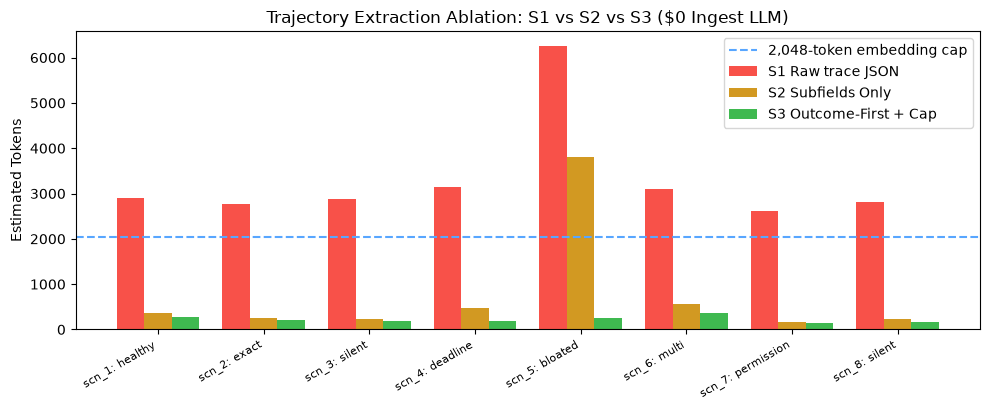

Ablation Summary: {
  "turn_count": 8,
  "s1_avg_bytes": 13256,
  "s1_avg_tokens": 3314,
  "s1_over_2048_count": 8,
  "s2_avg_bytes": 3023,
  "s2_avg_tokens": 756,
  "s2_over_2048_count": 1,
  "s3_avg_bytes": 887,
  "s3_avg_tokens": 222,
  "s3_over_2048_count": 0,
  "ingest_llm_cost_usd": 0.0
}


In [3]:
import matplotlib.pyplot as plt

sessions = [t['session_id'] for t in eval_turns]
short_labels = [
    (
        f'scn_{i + 1}: ' + s.replace('sess_', '').split('_')[1]
        if len(s.replace('sess_', '').split('_')) > 1
        else s.replace('sess_', '')[:14]
    )
    for i, s in enumerate(sessions)
]
s1_tokens = [t['ablation']['s1_tokens_est'] for t in eval_turns]
s2_tokens = [t['ablation']['s2_tokens_est'] for t in eval_turns]
s3_tokens = [t['ablation']['s3_tokens_est'] for t in eval_turns]

fig, ax = plt.subplots(figsize=(10, 4.2))
x = range(len(sessions))
w = 0.26
ax.bar([i - w for i in x], s1_tokens, width=w, label='S1 Raw trace JSON', color='#f85149')
ax.bar(list(x), s2_tokens, width=w, label='S2 Subfields Only', color='#d29922')
ax.bar([i + w for i in x], s3_tokens, width=w, label='S3 Outcome-First + Cap', color='#3fb950')
ax.axhline(2048, color='#58a6ff', linestyle='--', linewidth=1.5, label='2,048-token embedding cap')
ax.set_xticks(list(x))
ax.set_xticklabels(short_labels, rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Estimated Tokens')
ax.set_title('Trajectory Extraction Ablation: S1 vs S2 vs S3 ($0 Ingest LLM)')
ax.legend()
plt.tight_layout()
plt.show()

print('Ablation Summary:', json.dumps(_mask_proj(live_results['ablation_summary']), indent=2))

## Stage 3: BigQuery Dual Indexes (`AI.EMBED`, `SEARCH INDEX`, `IVF`) & 4-Layer Search

- Adds `_ai_index_trajectory_embedding GENERATED ALWAYS AS (AI.EMBED(_ai_index_trajectory, model => 'embeddinggemma-300m', task_type => 'RETRIEVAL_DOCUMENT')) STORED OPTIONS (asynchronous = TRUE)`
- Creates `SEARCH INDEX` (`LOG_ANALYZER`, column granularity)
- Creates unpartitioned `IVF` `VECTOR INDEX ... STORING (...)` only when `row_count >= 5000` (skips cleanly below `5,000` rows)
- Executes `Q1`–`Q5` across Layer 0 rules (`$0`, `0 ms`), Layer 1 (`gemini-decision-1` / Vertex `gemini-4-hydrogen` `thinking_level="LOW"`), `SEARCH`, `AI.SEARCH` (`rerank_score DESC`), RRF hybrid, and lazy Step-2 `trace` hydration

In [4]:
from analytics.index_and_search import run_index_and_search

search_results = run_index_and_search(
    project_id=PROJECT_ID,
    dataset_id=DATASET_ID,
    events_table=TABLE_ID,
    eval_turns_table=EVAL_TURNS_TABLE,
    location=BQ_LOCATION,
    vertex_location=AGENT_LOCATION,
    ai_generate_endpoint=MODEL_NAME,
    connection_id=BQML_CONNECTION_ID or None,
    input_json=live_json_path,
    output_json=search_json_path,
    offline=DEMO_MOCK_LIVE,
)

print('Index Status:', json.dumps(_mask_proj(search_results['index_status']), indent=2))
for q in search_results['queries']:
  rd = q['router_decision']
  print(f"{q['query_id']} [{rd['layer']} -> {rd['mode']}] step1_bytes={q['step1_bytes_processed']} hits={len(q['step1_hits'])}")

Index Status: {
  "ai_embed_column": "OK",
  "search_index": "SCAN_FALLBACK_BELOW_10GIB",
  "vector_index": "SKIPPED_BELOW_5000_ROWS",
  "row_count": 8,
  "embeddings_ready": 8,
  "warnings": []
}
q1_exact_error [L0_RULE -> KEYWORD] step1_bytes=8634 hits=3
q2_quoted_phrase [L0_RULE -> KEYWORD] step1_bytes=8634 hits=1
q3_nl_contradiction [L1_DECISIONS_API -> NATURAL_LANGUAGE] step1_bytes=57802 hits=5
q4_nl_retry_loop [L1_DECISIONS_API -> NATURAL_LANGUAGE] step1_bytes=57802 hits=5
q5_hybrid_mixed [L0_RULE -> HYBRID] step1_bytes=57802 hits=5


## Stage 4: Scoped `AI.GENERATE` Verification & Modeled 8-Lever Eval Cost Cascade

Projects four evaluation architectures analytically from live `S1`/`S3` byte counts and observed `L0`/`L1` latencies under uniform `gemini-4-hydrogen` judge pricing (`$0.30/1M` input, `$2.50/1M` output for Arms 2-4 vs `$3.00/$15.00` frontier Arm 1): naive all-rows raw-`trace` frontier judging (`Arm 1`) down to the full 8-lever cascade (`Arm 4`: deterministic `S3` trim, `eval_turns` scope, Layer 0/1 routing, `thinking_level="LOW"` `gemini-4-hydrogen` verification strictly on `top_k` candidates).

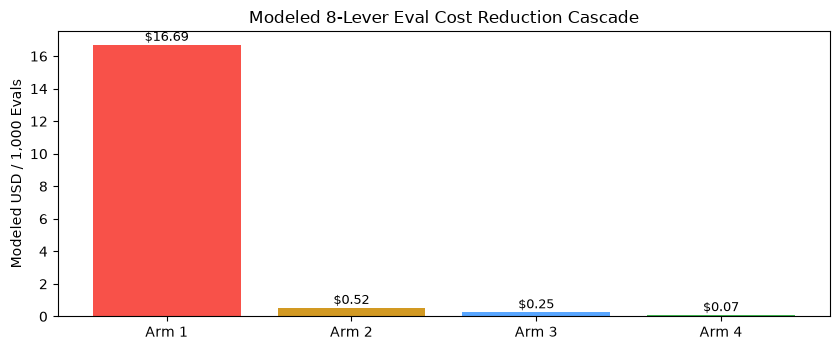

In [5]:
from analytics.pattern_to_eval import run_pattern_to_eval

pattern_report = run_pattern_to_eval(
    project_id=PROJECT_ID,
    dataset_id=DATASET_ID,
    eval_turns_table=EVAL_TURNS_TABLE,
    location=BQ_LOCATION,
    input_json=live_json_path,
    search_json=search_json_path,
    output_json=pattern_json_path,
    eval_suite_output=suite_json_path,
    offline=DEMO_MOCK_LIVE,
)
eval_suite_dict = json.loads(
    Path(pattern_report['eval_suite_path']).read_text(encoding='utf-8')
)

cascade = pattern_report['cost_cascade_ablation']
fig, ax = plt.subplots(figsize=(8.5, 3.6))
arms = [f'Arm {i + 1}' for i, _ in enumerate(cascade)]
costs = [c['cost_per_1k_usd'] for c in cascade]
bars = ax.bar(arms, costs, color=['#f85149', '#d29922', '#58a6ff', '#3fb950'])
ax.set_ylabel('Modeled USD / 1,000 Evals')
ax.set_title('Modeled 8-Lever Eval Cost Reduction Cascade')
for b, c in zip(bars, costs):
  ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.25, f'${c:.2f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

## Stage 5: Pattern Discovery -> `bigquery_agent_analytics.EvalSuite` & Showcase HTML

Converts discovered failure cohorts (`SILENT_CONTRADICTION_CANDIDATE`, `TOOL_LOOP`, `TOKEN_BLOAT`, `EXACT_ERROR_SPIKE`) into a balanced `EvalSuite`, validates it with `suite.check_health()`, and writes the self-contained `0600` Adaptive Workbench HTML showcase.

In [6]:
from bigquery_agent_analytics import EvalSuite
from report.build_showcase_html import build_showcase_html

suite = EvalSuite.from_json(json.dumps(eval_suite_dict))
health = suite.check_health()
print('EvalSuite Health:', health.model_dump())

showcase_res = build_showcase_html(
    live_json=live_json_path,
    search_json=search_json_path,
    pattern_json=pattern_json_path,
    eval_suite_json=suite_json_path,
    demo_fixture=False,
    output_path=out_dir / 'showcase.html',
)
print('Showcase HTML written:', _mask_proj(showcase_res))

EvalSuite Health: {'total_tasks': 6, 'capability_tasks': 2, 'regression_tasks': 4, 'positive_cases': 2, 'negative_cases': 4, 'saturated_task_ids': [], 'balance_ratio': 0.3333333333333333, 'warnings': []}
Showcase HTML written: {'output_path': 'examples/combined_cuj_trace_search_demo/reports/notebook_run/showcase.html', 'bytes': 391243, 'mode': 'Live BigQuery Run'}
